# nf-core pipeline edges vs. citation-order edges

Compare ordered tool co-citations with tool pairs in chosen workflows

- **Workflows:** `/data/*/biotools_edges.csv` (CHOOSE ONE)
- **Citations:** `../edges-processed/directed_edges.csv` (`citation-order/` steps 3 to 5): tool A is cited before tool B in `n_articles` articles

Each pipeline pair is put in its main pipeline direction, `source` → `target`. Then both sources get a direction ratio, from 0 to 1: the share of the counts that go `source` → `target`.

`distance = |wf_dir - cit_dir|` says how well the two agree: 0 = the same ratio, 1 = opposite directions (all pipelines one way, all articles the other).

In [1]:
import duckdb

MAX_CONFIDENCE = 3   # workflow edges to use: 1 = curated or meta.yml only, 2 = + bio.tools match, 3 = all (+ prefix match)
MIN_ARTICLES = 1    # pairs with fewer articles are left out of the summary


WF_DATA = "../workflows/data/biotools"
CITATIONS = "../directed-graph/edges-processed/directed_edges.csv"
# WORKFLOWS = f"{WF_DATA}/galaxy/biotools_edges.csv"
# WORKFLOWS = f"{WF_DATA}/nextflow/biotools_edges.csv"
WORKFLOWS = f"{WF_DATA}/nf-core/biotools_edges.csv"

DROP_BALANCED = True  # TEMPORARY: leave out pairs with wf_dir exactly 0.5 (as many workflows both ways)

con = duckdb.connect()
# The nf-core table has no confidence column (yet): then confidence is empty and MAX_CONFIDENCE is not used.
HAS_CONFIDENCE = "confidence" in con.sql(f"SELECT * FROM '{WORKFLOWS}' LIMIT 0").columns
if not HAS_CONFIDENCE:
    print(f"No confidence column in {WORKFLOWS}: using all edges, no confidence filter or colours")
con.execute(f"""
    CREATE OR REPLACE TABLE wf AS
    SELECT lower(source) AS source, lower(target) AS target, n_workflows,
           {"confidence" if HAS_CONFIDENCE else "NULL::INTEGER AS confidence"}
    FROM '{WORKFLOWS}' {f"WHERE confidence <= {MAX_CONFIDENCE}" if HAS_CONFIDENCE else ""}
""")
con.execute(f"CREATE OR REPLACE TABLE cit AS SELECT source, target, n_articles FROM '{CITATIONS}'")
con.execute("CREATE OR REPLACE TABLE cit_tools AS SELECT source AS tool FROM cit UNION SELECT target FROM cit")

# One row per workflow pair in its main direction, with the counts of both sources both ways.
con.execute(f"""
    CREATE OR REPLACE TABLE pairs AS
    WITH counts AS (
        SELECT f.source, f.target,
               f.n_workflows AS wf_fwd, coalesce(r.n_workflows, 0) AS wf_rev,
               coalesce(cf.n_articles, 0) AS cit_fwd, coalesce(cr.n_articles, 0) AS cit_rev,
               greatest(f.confidence, coalesce(r.confidence, f.confidence)) AS confidence,  -- the weaker of both directions
               f.source IN (SELECT tool FROM cit_tools) AND f.target IN (SELECT tool FROM cit_tools) AS both_in_cit
        FROM wf f
        LEFT JOIN wf r ON r.source = f.target AND r.target = f.source
        LEFT JOIN cit cf ON cf.source = f.source AND cf.target = f.target
        LEFT JOIN cit cr ON cr.source = f.target AND cr.target = f.source
        WHERE f.n_workflows > coalesce(r.n_workflows, 0)                -- the main direction,
           OR (f.n_workflows = r.n_workflows AND f.source < f.target)  -- on a tie the alphabetical one
    ),
    ratios AS (
        SELECT *,
               wf_fwd / (wf_fwd + wf_rev) AS wf_dir,
               cit_fwd / nullif(cit_fwd + cit_rev, 0) AS cit_dir
        FROM counts
    )
    SELECT *, abs(wf_dir - cit_dir) AS distance FROM ratios
    {"WHERE wf_dir <> 0.5" if DROP_BALANCED else ""}
""")

No confidence column in ../workflows/data/biotools/nf-core/biotools_edges.csv: using all edges, no confidence filter or colours


## Print edges

One row per workflow pair, ordered by number of occurances in workflows.

In [2]:
con.sql("""
    SELECT source, target, wf_fwd, wf_rev, round(wf_dir, 2) AS wf_dir,
           cit_fwd, cit_rev, round(cit_dir, 2) AS cit_dir, round(distance, 2) AS distance
    FROM pairs ORDER BY wf_fwd + wf_rev DESC, cit_fwd + cit_rev DESC
""").show(max_rows=1000)

┌───────────────────────────────────────┬───────────────────────────────────────┬────────┬────────┬────────┬─────────┬─────────┬─────────┬──────────┐
│                source                 │                target                 │ wf_fwd │ wf_rev │ wf_dir │ cit_fwd │ cit_rev │ cit_dir │ distance │
│                varchar                │                varchar                │ int64  │ int64  │ double │  int64  │  int64  │ double  │  double  │
├───────────────────────────────────────┼───────────────────────────────────────┼────────┼────────┼────────┼─────────┼─────────┼─────────┼──────────┤
│ fastqc                                │ multiqc                               │     72 │      0 │    1.0 │       0 │       0 │    NULL │     NULL │
│ samtools                              │ multiqc                               │     38 │      2 │   0.95 │     372 │     897 │    0.29 │     0.66 │
│ samtools                              │ picard_tools                          │     20 │     16 │ 

## Statistics

Comparison of tool pairs in co-citation graph and in nf-core pipelines.


In [3]:
# Distance statistics for the pairs co-cited in at least 1, 5, 10, ... articles, optionally only a subset of pairs.
def stats(where="true"):
    con.sql(f"""
        SELECT min_articles,
               count(*)                    AS pairs_compared,
               round(avg(distance), 2)     AS mean_distance,
               round(median(distance), 2)  AS median_distance
        FROM pairs, (VALUES (1), (5), (10), (20), (50), (100), (200)) v(min_articles)
        WHERE cit_fwd + cit_rev >= min_articles AND {where}
        GROUP BY min_articles ORDER BY min_articles
    """).show()


stats()  # all pairs

┌──────────────┬────────────────┬───────────────┬─────────────────┐
│ min_articles │ pairs_compared │ mean_distance │ median_distance │
│    int32     │     int64      │    double     │     double      │
├──────────────┼────────────────┼───────────────┼─────────────────┤
│            1 │            785 │          0.31 │            0.25 │
│            5 │            626 │           0.3 │            0.25 │
│           10 │            562 │           0.3 │            0.24 │
│           20 │            486 │           0.3 │            0.24 │
│           50 │            381 │          0.29 │            0.22 │
│          100 │            300 │          0.28 │             0.2 │
│          200 │            211 │          0.25 │            0.17 │
└──────────────┴────────────────┴───────────────┴─────────────────┘



In [4]:
stats("wf_fwd + wf_rev >= 2")  # pairs in at least 2 workflows

┌──────────────┬────────────────┬───────────────┬─────────────────┐
│ min_articles │ pairs_compared │ mean_distance │ median_distance │
│    int32     │     int64      │    double     │     double      │
├──────────────┼────────────────┼───────────────┼─────────────────┤
│            1 │            245 │           0.3 │            0.24 │
│            5 │            216 │          0.29 │            0.23 │
│           10 │            207 │          0.29 │            0.23 │
│           20 │            188 │          0.28 │             0.2 │
│           50 │            161 │          0.28 │            0.19 │
│          100 │            130 │          0.26 │            0.16 │
│          200 │             98 │          0.23 │            0.16 │
└──────────────┴────────────────┴───────────────┴─────────────────┘



In [5]:
if HAS_CONFIDENCE:
    stats("confidence = 1")  # pairs mapped by curation or nf-core meta.yml only

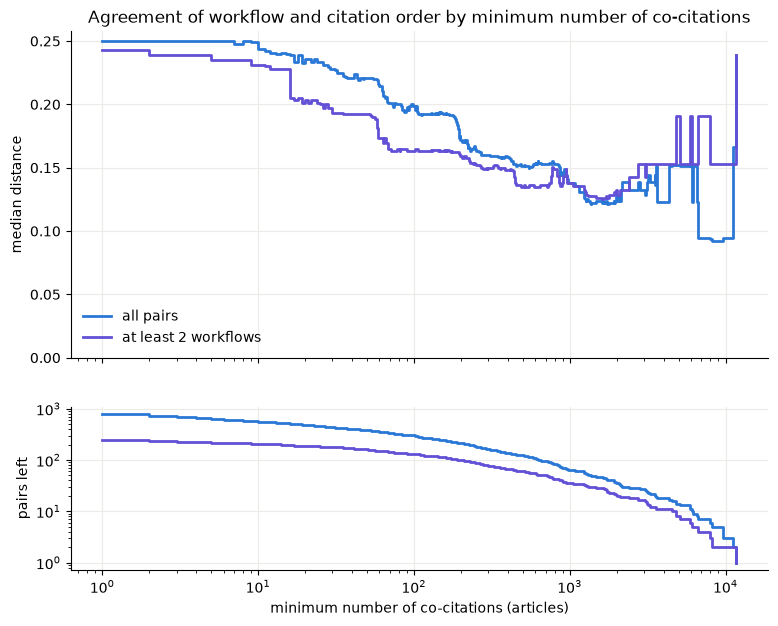

In [6]:
# Median distance for each subset at every minimum number of co-citations, and how many pairs are left.
# The confidence curve is only drawn when the edges have a confidence column.
import matplotlib.pyplot as plt

SUBSETS = [("all pairs", "true", "#2a78d6"),
           ("at least 2 workflows", "wf_fwd + wf_rev >= 2", "#6250d6")]
if HAS_CONFIDENCE:
    SUBSETS.append(("confidence 1 (curated or meta)", "confidence = 1", "#eda100"))

fig, (ax_median, ax_pairs) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=[2, 1])
for label, where, colour in SUBSETS:
    rows = con.execute(f"""
        WITH p AS (SELECT cit_fwd + cit_rev AS n_articles, distance FROM pairs WHERE cit_fwd + cit_rev >= 1 AND {where})
        SELECT t.n_articles AS min_articles, median(p.distance), count(*)
        FROM (SELECT DISTINCT n_articles FROM p) t JOIN p ON p.n_articles >= t.n_articles
        GROUP BY t.n_articles ORDER BY t.n_articles
    """).fetchall()
    x, median_distance, n_pairs = zip(*rows)
    ax_median.step(x, median_distance, where="post", color=colour, linewidth=2, label=label)
    ax_pairs.step(x, n_pairs, where="post", color=colour, linewidth=2)

ax_median.set(ylabel="median distance", ylim=(0, None),
              title="Agreement of workflow and citation order by minimum number of co-citations")
ax_median.legend(frameon=False)
ax_pairs.set(xscale="log", yscale="log", xlabel="minimum number of co-citations (articles)", ylabel="pairs left")
for ax in (ax_median, ax_pairs):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
plt.show()

In [7]:
# Count of pairs with at least 2 workflows
con.execute("SELECT count(*) FROM pairs WHERE wf_fwd + wf_rev >= 2",
                       ).fetchall()


[(440,)]

In [8]:
# Plot of workflow direction vs. citation direction, one dot per pair, one panel per minimum number of articles.
# On the diagonal both sources have the same ratio.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

BLUE = "#2a78d6"
COLOURS = {1: ("#2a78d6", "1: curated or meta"), 2: ("#eb6834", "2: bio.tools match"), 3: ("#1baf7a", "3: prefix match")}
SIZES = [("1 workflow", 1, 2, 12), ("2-4 workflows", 2, 5, 25), ("5+ workflows", 5, 10**9, 50)]


def dot_size(n_workflows):
    return next(size for _, low, high, size in SIZES if low <= n_workflows < high)


def legend(ax, items, title=None):
    """A legend of round markers: items are (label, colour, area)."""
    handles = [Line2D([], [], marker="o", linestyle="", color=colour, markersize=area ** 0.5) for _, colour, area in items]
    ax.add_artist(ax.legend(handles, [label for label, _, _ in items], title=title, loc="lower left", frameon=False))


def plot_pairs(min_articles_list=(1, 20, 100), colour_by_confidence=False, size_by_workflows=False):
    colour_by_confidence = colour_by_confidence and HAS_CONFIDENCE  # no colours without a confidence column
    fig, axes = plt.subplots(1, len(min_articles_list), figsize=(5 * len(min_articles_list), 5.5), sharey=True)
    for ax, min_articles in zip(axes, min_articles_list):
        rows = con.execute("""
            SELECT wf_dir, cit_dir, wf_fwd + wf_rev, confidence FROM pairs
            WHERE cit_fwd + cit_rev >= ? ORDER BY confidence DESC  -- confidence 1 drawn last, on top
        """, [min_articles]).fetchall()
        x, y, n_workflows, confidence = zip(*rows)
        ax.plot([0, 1], [0, 1], color="#b0afa8", linewidth=1, zorder=1)
        ax.scatter(x, y,
                   s=[dot_size(n) for n in n_workflows] if size_by_workflows else 20,
                   c=[COLOURS[c][0] for c in confidence] if colour_by_confidence else BLUE,
                   alpha=0.6, edgecolor="white", linewidth=0.5, zorder=2)
        ax.set(xlim=(0, 1.02), ylim=(-0.02, 1.02), aspect="equal",
               xlabel="order of tool pairs in workflows",
               title=f"at least {min_articles} co-citations: {len(rows)} tool pairs")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(color="#ecebe7", linewidth=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("order of tool pairs in co-citations")
    if size_by_workflows:
        legend(axes[0], [(label, "#9a9a94", size) for label, _, _, size in SIZES])
    if colour_by_confidence:
        legend(axes[1 if size_by_workflows else 0], [(label, colour, 36) for colour, label in COLOURS.values()],
               title="confidence")
    plt.show()

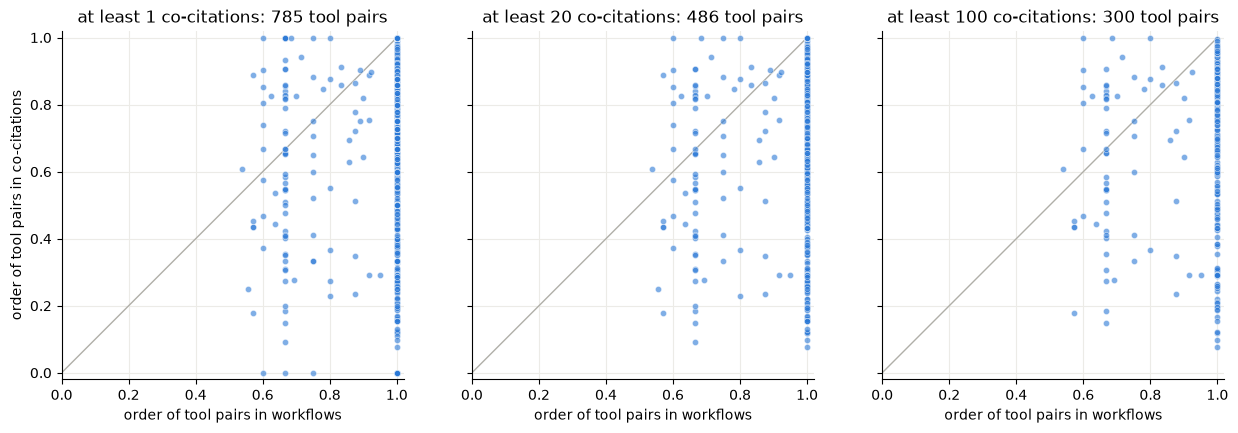

In [9]:
# All dots the same size and colour.
plot_pairs()

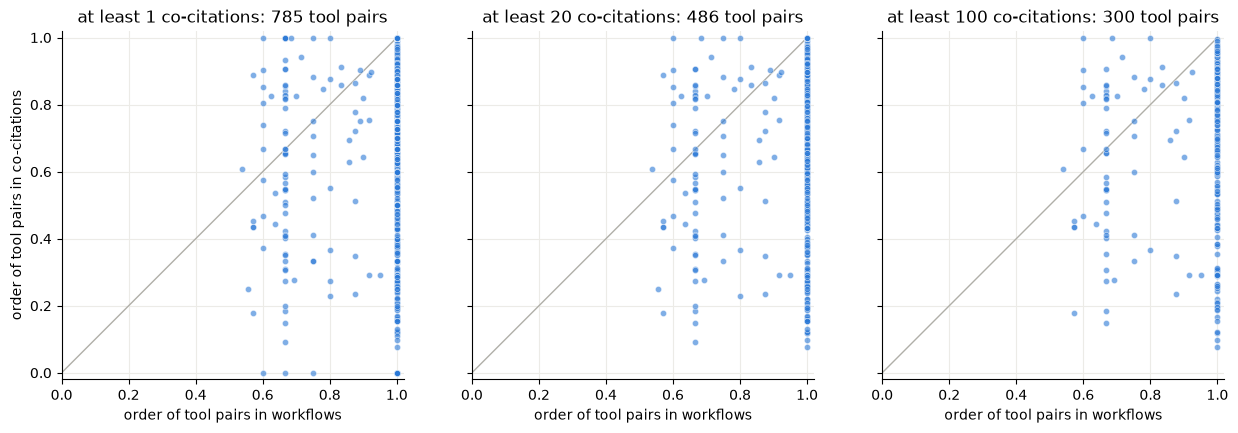

In [10]:
# Colour: mapping confidence of the pair.
plot_pairs(colour_by_confidence=True)

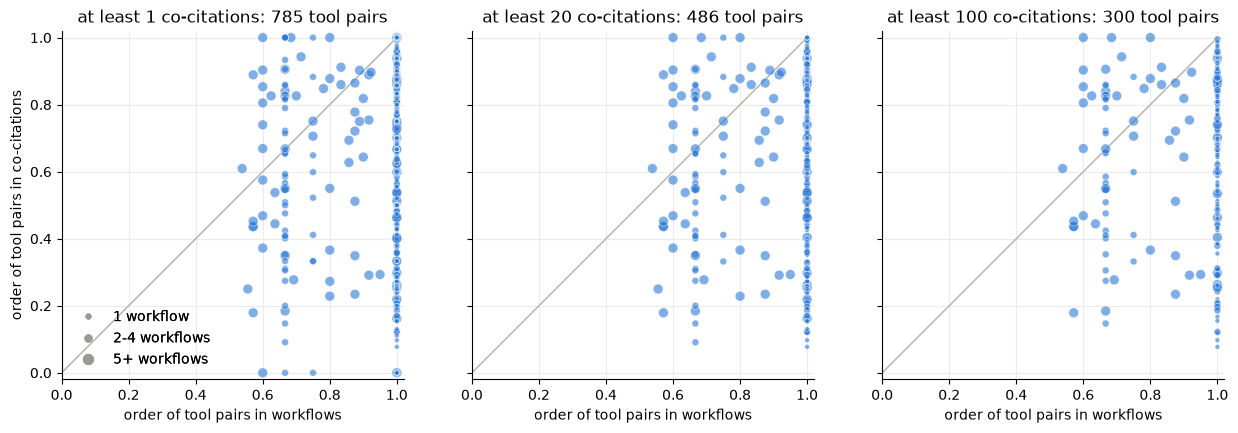

In [11]:
# Colour: mapping confidence. Dot size: number of workflows with the pair (1, 2 to 4, 5 or more).
plot_pairs(colour_by_confidence=True, size_by_workflows=True)

## Used edges statistics

How many workflow pairs could be in the citation graph (both tools are in it somewhere), and how many are.

In [12]:
con.sql("""
    UNPIVOT (
        SELECT count(*)                                         AS "workflow pairs",
               count(*) FILTER (both_in_cit)                    AS "both tools in the citation graph",
               count(*) FILTER (cit_dir IS NOT NULL)            AS "also a citation edge",
               count(*) FILTER (cit_fwd + cit_rev >= 5)         AS "citation edge, at least 5 articles",
               count(*) FILTER (cit_fwd + cit_rev >= 10)        AS "citation edge, at least 10 articles",
               count(*) FILTER (cit_fwd + cit_rev >= 20)        AS "citation edge, at least 20 articles"
        FROM pairs
    ) ON COLUMNS(*) INTO NAME measure VALUE pairs
""").show()

┌─────────────────────────────────────┬───────┐
│               measure               │ pairs │
│               varchar               │ int64 │
├─────────────────────────────────────┼───────┤
│ workflow pairs                      │  1906 │
│ both tools in the citation graph    │  1013 │
│ also a citation edge                │   785 │
│ citation edge, at least 5 articles  │   626 │
│ citation edge, at least 10 articles │   562 │
│ citation edge, at least 20 articles │   486 │
└─────────────────────────────────────┴───────┘



# More plots

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:

sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.3, "grid.linestyle": "--"})
COLOUR = "#f2634c"

In [15]:
direction_df = con.execute("""
    SELECT wf_dir, cit_dir,
           wf_fwd + wf_rev   AS wf_total,
           cit_fwd + cit_rev AS cit_total,
           confidence
    FROM pairs
    WHERE cit_fwd + cit_rev >= ? ORDER BY confidence DESC
""", [1]).df()

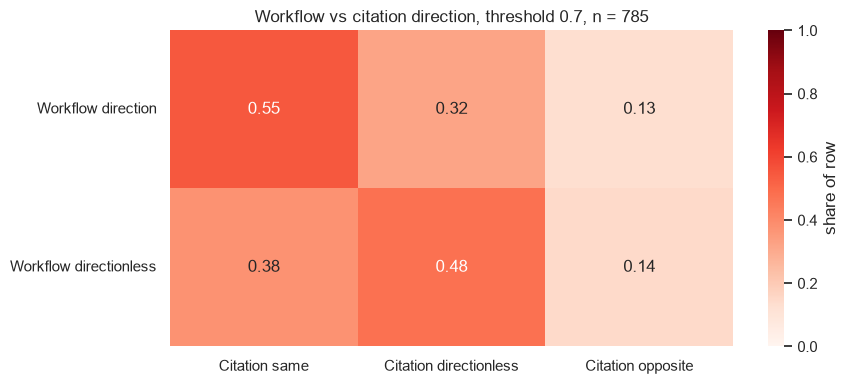

class_cit      same  directionless  opposite
class_wf                                    
direction       392            231        93
directionless    26             33        10
agreement when workflow has a direction: 0.55 (n = 716)
agreement when both have a clear direction: 0.81 (n = 485)


In [16]:
"""
Wf Direction
Wf Directionless
                cit same cit opposite cit directionless

"""
THRESHOLD = 0.70  # direction threshold; 1 - t is the opposite threshold

ROWS = ["direction", "directionless"]
COLS = ["same", "directionless", "opposite"]

# wf_dir is always >= 0.5 (main workflow direction), so only two row classes
direction_df["class_wf"] = np.where(direction_df["wf_dir"] > THRESHOLD, "direction", "directionless")
direction_df["class_cit"] = np.select(
    [direction_df["cit_dir"] > THRESHOLD, direction_df["cit_dir"] < 1 - THRESHOLD],
    ["same", "opposite"],
    default="directionless",
)

counts = (pd.crosstab(direction_df["class_wf"], direction_df["class_cit"])
            .reindex(index=ROWS, columns=COLS, fill_value=0))
norm = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(norm, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "share of row"})
ax.set_xticklabels([f"Citation {c}" for c in COLS])
ax.set_yticklabels([f"Workflow {r}" for r in ROWS], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"Workflow vs citation direction, threshold {THRESHOLD}, n = {len(direction_df)}")
plt.tight_layout()
plt.show()

print(counts)
d = counts.loc["direction"]
print("agreement when workflow has a direction:",
      round(d["same"] / d.sum(), 2) if d.sum() else "n/a", f"(n = {d.sum()})")
print("agreement when both have a clear direction:",
      round(d["same"] / (d["same"] + d["opposite"]), 2) if d["same"] + d["opposite"] else "n/a",
      f"(n = {d['same'] + d['opposite']})")

85 626


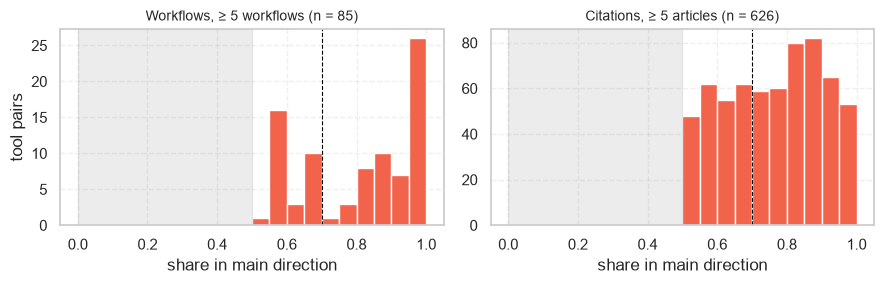

In [17]:
MIN_CIT = 5   # articles
MIN_WF = 5    # workflows
BINS = np.linspace(0, 1, 21)  # 0.05 bins

s_wf = direction_df.loc[direction_df["wf_total"] >= MIN_WF, "wf_dir"]
s_cit = direction_df.loc[direction_df["cit_total"] >= MIN_CIT, "cit_dir"]
s_cit = np.maximum(s_cit, 1 - s_cit)  # update so its also on one side of 0.5: 0.2 -> 0.8

print(len(s_wf), len(s_cit))

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
axes[0].hist(s_wf, bins=BINS, color=COLOUR)
axes[0].set_title(f"Workflows, ≥ {MIN_WF} workflows (n = {len(s_wf)})", fontsize=10)
axes[1].hist(s_cit, bins=BINS, color=COLOUR)
axes[1].set_title(f"Citations, ≥ {MIN_CIT} articles (n = {len(s_cit)})", fontsize=10)

for ax in axes:
    ax.axvspan(0, 0.5, color="grey", alpha=0.15)  # not possible: main direction by definition
    ax.axvline(THRESHOLD, color="black", ls="--", lw=0.8)
    ax.set_xlabel("share in main direction")
axes[0].set_ylabel("tool pairs")
plt.tight_layout()
plt.show()

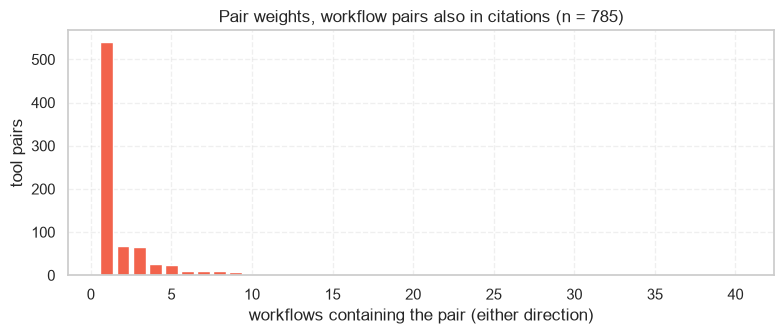

In [18]:
counts_wf = direction_df["wf_total"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts_wf.index, counts_wf.values, width=0.8, color=COLOUR)
ax.set_xlabel("workflows containing the pair (either direction)")
ax.set_ylabel("tool pairs")
ax.set_title(f"Pair weights, workflow pairs also in citations (n = {len(direction_df)})")
plt.tight_layout()
plt.show()